# Código Cristalizador SQM
### ¿Qué tiene que resolver el código?

Un cristalizador evaporativo MSMPR se describe con tres balances acoplados:

- Balance de población (PBE): cómo cambia la distribución de tamaños n(L,t) por crecimiento, nucleación y descarga del producto. Es una EDP. Al dividir el eje de tamaños en celdas (volúmenes finitos) se convierte en un sistema de EDOs.
- Balance de masa de soluto y de solvente: el KNO₃ que pasa de la solución al cristal, y el agua que sale como vapor. Aquí entra la evaporación.
- Balance de energía: el calor que se entrega, el que se va en evaporar agua y el calor de cristalización.

En resumen: un sistema grande de EDOs, propiedades termodinámicas (solubilidad, presión de vapor, calor latente), datos de planta para comparar y gráficos. 

### 1. Importamos librerías necesarias

In [1]:
# =========================================================
# 0. Librerías
# =========================================================
# Biblioteca estándar
from dataclasses import dataclass, field   # parámetros ordenados y con nombre
import copy                                 # duplicar casos para sensibilidad

# Cálculo numérico
import numpy as np                          # vectores: n(L), flujos, momentos
from scipy.integrate import solve_ivp       # integrador de EDOs (rígido: BDF/LSODA)
from scipy.optimize import brentq, least_squares  # ec. algebraicas y ajuste de parámetros

# Datos y gráficos
import pandas as pd                         # lectura de los Excel de SQM (requiere openpyxl)
import matplotlib.pyplot as plt             # CSD, trayectorias, diagnósticos

# Verificación rápida de versiones (útil para reproducibilidad del informe)
import scipy, matplotlib
print("numpy", np.__version__, "| scipy", scipy.__version__,
      "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

numpy 1.26.0 | scipy 1.16.3 | pandas 3.0.1 | matplotlib 3.10.8


## 2. Termodinámica del sistema KNO₃–KClO₄ en la salmuera de SQM

Esta sección define **todo lo que el resto del modelo necesita saber del equilibrio sólido–líquido**: cuánto KNO₃ y cuánto KClO₄ caben en el licor a cada temperatura, y cómo eso cambia con el Mg y el NaNO₃. El resto del código (balances, PBE, perclorato en el cristal) solo llama a las funciones que se definen aquí, de modo que la sobresaturación queda definida **en un único lugar**.

**Ruta de cálculo (paso a paso):**

1. Curvas de solubilidad de KNO₃ y KClO₄ en **agua pura**, ajustadas a datos de bibliografía con la ecuación de Apelblat (modelo empírico ampliamente utilizado en química e ingeniería química para correlacionar y predecir la solubilidad de solutos sólidos en disolventes líquidos (puros o mezclas) en función de la temperatura).
2. Producto de solubilidad aparente de cada sal, $K'_{sp}(T) = m_{sat}(T)^2$ (sales 1:1).
3. Extensión a la salmuera con **efecto de ion común** (el K⁺ y el NO₃⁻ son compartidos) y un **factor de actividad** $\Gamma$ que corrige la no idealidad de la mezcla.
4. Calibración de $\Gamma_{KClO_4}$ con el ensayo de SQM sobre SSKd.
5. Sobresaturación única, índice de saturación del KClO₄ y holgura térmica.

**Convención de unidades.** Dentro de esta sección las concentraciones se expresan en **molalidad** (mol por kg de agua). Es la base natural para un cristalizador evaporativo: cuando se evapora agua, la molalidad de las especies que no cristalizan sube en proporción directa, sin depender de la densidad del licor.

In [2]:
# =========================================================
# 2.1 Constantes y datos de bibliografía (agua pura)
# =========================================================
R_GAS = 8.314            # J/(mol K)
M = {"KNO3": 101.10, "KClO4": 138.55, "K": 39.10, "NO3": 62.00,
     "ClO4": 99.45, "Mg": 24.305, "Na": 22.99, "NaNO3": 84.99}   # g/mol

# Solubilidad de KNO3 en agua [g KNO3 / 100 g H2O].
# Fuente: base de datos chemister.ru (KNO3, id 513), valores coincidentes con tablas escolares
# derivadas del CRC (31,6 / 45,8 / 63,9 g a 20 / 30 / 40 °C). VERIFICAR contra Perry o CRC antes del informe.
SOL_KNO3_AGUA = pd.DataFrame({
    "T_C":      [10,   20,   25,   30,   40,   60,    80,    100],
    "g_100g":   [21.2, 31.6, 37.9, 46.0, 63.9, 110.1, 168.8, 243.6]})

# Solubilidad de KClO4 en agua [g KClO4 / 100 mL H2O ~ g / 100 g H2O].
# Fuentes: chemister.ru (KClO4, id 519) y hoja de seguridad J.T. Baker, compilados en Wikipedia
# (0, 25, 40 y 100 °C); 17 g/L a 20 °C de la ficha Merck/ChemicalBook.
# OJO: los puntos de 20, 25 y 40 °C no son del todo consistentes entre sí (ver residuos del ajuste).
# Pendiente: reemplazar por una tabla única (Linke & Seidell o CRC).
SOL_KCLO4_AGUA = pd.DataFrame({
    "T_C":    [0,    20,  25,  40,   100],
    "g_100g": [0.76, 1.7, 1.5, 4.76, 21.08]})

def g100_a_molal(g_100g, sal):
    """g de sal / 100 g agua -> mol/kg agua."""
    return np.asarray(g_100g) * 10.0 / M[sal]

display(SOL_KNO3_AGUA.T, SOL_KCLO4_AGUA.T)

,0,1,2,3,4,5,6,7
T_C,10.0,20.0,25.0,30.0,40.0,60.0,80.0,100.0
g_100g,21.2,31.6,37.9,46.0,63.9,110.1,168.8,243.6


,0,1,2,3,4
T_C,0.00,20.0,25.0,40.00,100.00
g_100g,0.76,1.7,1.5,4.76,21.08


### 2.2 Ajuste de las curvas binarias (ecuación de Apelblat)

La ecuación de Apelblat es una forma estándar y con base termodinámica para la solubilidad de sólidos en función de la temperatura:

$$\ln m_{sat}(T) = A + \frac{B}{T} + C\,\ln T \qquad (T \text{ en K})$$

El término $B/T$ viene de la ecuación de van't Hoff (entalpía de disolución) y $C \ln T$ permite que esa entalpía cambie con la temperatura. Se ajusta en escala logarítmica para que todos los puntos pesen en error relativo.

KNO3: A=108.242, B=-7510.7, C=-14.3428 | error relativo máx = 1.2 %
KClO4: A=16.736, B=-3820.8, C=-1.0216 | error relativo máx = 38.2 %


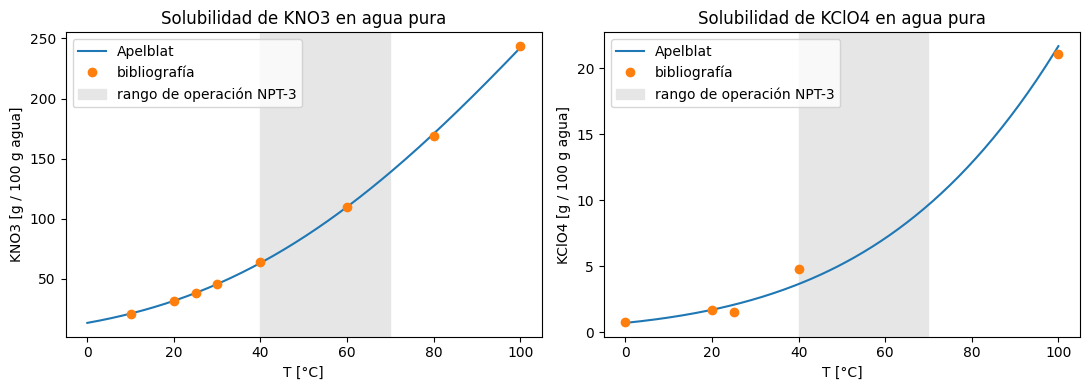

In [3]:
def apelblat(p, T_C):
    TK = np.asarray(T_C, dtype=float) + 273.15
    return np.exp(p[0] + p[1] / TK + p[2] * np.log(TK))

def ajustar_apelblat(T_C, m):
    res = least_squares(lambda p: np.log(apelblat(p, T_C)) - np.log(m), x0=[0.0, -1000.0, 0.0])
    return res.x, res.fun        # parámetros y residuos en ln(m)

P_APEL = {}
for sal, tabla in (("KNO3", SOL_KNO3_AGUA), ("KClO4", SOL_KCLO4_AGUA)):
    m_dat = g100_a_molal(tabla["g_100g"], sal)
    P_APEL[sal], resid = ajustar_apelblat(tabla["T_C"].values, m_dat)
    print(f"{sal}: A={P_APEL[sal][0]:.3f}, B={P_APEL[sal][1]:.1f}, C={P_APEL[sal][2]:.4f} | "
          f"error relativo máx = {100*np.max(np.abs(np.expm1(resid))):.1f} %")

def m_sat_agua(sal, T_C):
    """Solubilidad en agua pura [mol/kg agua]."""
    return apelblat(P_APEL[sal], T_C)

def Ksp_ap(sal, T_C):
    """Producto de solubilidad aparente de una sal 1:1 en agua pura: K'sp = m_sat^2 [(mol/kg)^2].
    Absorbe los coeficientes de actividad del sistema binario saturado."""
    return m_sat_agua(sal, T_C) ** 2

# Gráfico de verificación
Tg = np.linspace(0, 100, 201)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (sal, tabla) in zip(ax, (("KNO3", SOL_KNO3_AGUA), ("KClO4", SOL_KCLO4_AGUA))):
    a.plot(Tg, m_sat_agua(sal, Tg) * M[sal] / 10, label="Apelblat")
    a.plot(tabla["T_C"], tabla["g_100g"], "o", label="bibliografía")
    a.axvspan(40, 70, color="0.9", label="rango de operación NPT-3")
    a.set(xlabel="T [°C]", ylabel=f"{sal} [g / 100 g agua]", title=f"Solubilidad de {sal} en agua pura")
    a.legend()
plt.tight_layout(); plt.show()

### 2.3 Extensión a la salmuera: ion común y factor de actividad

En el licor de SQM el K⁺ está compartido por el KNO₃ y el KClO₄, y el NO₃⁻ también aporta el NaNO₃ y el Mg(NO₃)₂. Para una sal 1:1 la condición de saturación es

$$m_{K^+}\, m_{X^-} = \Gamma_X \, K'_{sp,X}(T), \qquad X \in \{NO_3^-,\ ClO_4^-\}$$

- $K'_{sp,X}(T)$ es el producto aparente del sistema binario (sección 2.2).
- $\Gamma_X$ corrige la diferencia de coeficientes de actividad entre la salmuera y el binario saturado. Con $\Gamma = 1$ queda el **efecto de ion común ideal**.
- Para el efecto del Mg se usa una corrección empírica: $\ln\Gamma_X = \ln\Gamma_{X,0} + k_{X,Mg}\,(m_{Mg} - m_{Mg,ref})$.

**Consecuencias que salen del propio modelo (sin parámetros extra):**

- Como el licor tiene mucho K⁺ (KNO₃ casi saturado), la solubilidad del KClO₄ es **mucho menor que en agua pura**.
- Si baja el NaNO₃, baja el exceso de nitrato, la sal KNO₃ admite más K⁺ disuelto y, por ion común, **baja la solubilidad del KClO₄**. Es justo lo que reportó SQM.
- El Mg aporta nitrato (lo que por sí solo subiría la solubilidad del KClO₄), pero SQM observa lo contrario. Por eso el efecto del Mg **tiene que entrar por $k_{ClO_4,Mg} < 0$** y calibrarse con datos.

**Sobresaturación única.** Para una sal 1:1 se define

$$S_X = \sqrt{\frac{m_{K^+}\, m_{X^-}}{\Gamma_X\, K'_{sp,X}(T)}}, \qquad \sigma_X = S_X - 1$$

En agua pura se reduce a $\sigma = m/m_{sat} - 1 = \Delta C/C^*$, la misma definición del modelo anterior, así que es compatible con las cinéticas de bibliografía. **Todo el código usa `sobresaturacion()`**; ninguna otra función calcula σ por su cuenta.

In [4]:
# =========================================================
# 2.3 Funciones de equilibrio en la salmuera
# =========================================================
# Parámetros de actividad. Procedencia: 'calibrado' / 'supuesto' / 'pendiente'.
TERMO = {
    "lnGamma0": {"KNO3": 0.0, "KClO4": 0.0},          # se calibra KClO4 en 2.5; KNO3 pendiente (datos de MLK)
    "k_Mg":     {"KNO3": 0.0, "KClO4": 0.0},          # [kg/mol] pendiente: requiere ensayos a distinto Mg
    "m_Mg_ref": 2.0,                                  # [mol/kg] referencia del ajuste (≈ Mg del ensayo SQM)
}
PROCEDENCIA_TERMO = {"lnGamma0.KNO3": "pendiente (MLK)", "lnGamma0.KClO4": "calibrado en 2.5",
                     "k_Mg.KNO3": "pendiente", "k_Mg.KClO4": "pendiente (signo esperado < 0)"}

def Gamma(sal, m_Mg, termo=TERMO):
    return np.exp(termo["lnGamma0"][sal] + termo["k_Mg"][sal] * (m_Mg - termo["m_Mg_ref"]))

def sobresaturacion(sal, T_C, comp, termo=TERMO):
    """ÚNICA definición de sobresaturación del modelo.
    comp: dict con molalidades [mol/kg agua] de 'K', 'NO3', 'ClO4', 'Mg'.
    Devuelve sigma = S - 1, con S = sqrt(IAP / (Gamma * K'sp)). sigma < 0 significa subsaturado."""
    anion = {"KNO3": "NO3", "KClO4": "ClO4"}[sal]
    IAP = comp["K"] * comp[anion]
    return np.sqrt(IAP / (Gamma(sal, comp["Mg"], termo) * Ksp_ap(sal, T_C))) - 1.0

def m_K_eq_KNO3(T_C, comp, termo=TERMO):
    """K+ disuelto [mol/kg] cuando el licor está en equilibrio con KNO3 sólido.
    Al cristalizar x mol/kg de KNO3 se pierde lo mismo de K+ y de NO3-: el exceso d = NO3 - K se conserva."""
    d = comp["NO3"] - comp["K"]
    Kp = Gamma("KNO3", comp["Mg"], termo) * Ksp_ap("KNO3", T_C)
    return 0.5 * (-d + np.sqrt(d * d + 4.0 * Kp))

def m_ClO4_sat(T_C, m_K, m_Mg, termo=TERMO):
    """Solubilidad del perclorato [mol/kg] para un K+ dado (ion común)."""
    return Gamma("KClO4", m_Mg, termo) * Ksp_ap("KClO4", T_C) / m_K

### 2.4 Composición del licor de alimentación (SSK / SSKd)

Se usan las medianas de los análisis químicos de SQM (`AQ SSKd.xlsx`, octubre 2026, 356 muestras de SSK y 180 de SSKd). Se interpretan como **g/L de solución**, con NO₃ total informado también como "NaNO₃ equivalente" (681 × 62/85 ≈ 497, que coincide con la columna NO₃).

Para pasar de g/L a mol/kg de agua hace falta **cuánta agua hay en un litro de licor** ($w_{agua}$). Se toma del informe de parámetros de SQM para la corriente 334 SSK-d: fracción de agua 0,3994 kg/kg y densidad 1518 kg/m³, es decir, $w_{agua}$ = 0,606 kg/L. Es un dato de una sola corriente reconciliada, así que conviene verificarlo con la densidad y la humedad medidas del SSKd.

⚠ **Unidades por confirmar con SQM.** Además, los cationes medidos superan a los aniones medidos en ~4,4 eq/L. Lo más probable es que sea cloruro no analizado (NaCl/KCl arrastrado desde conversión), y eso también hay que confirmarlo.

In [5]:
# Medianas AQ SSKd.xlsx (oct-2026) [g/L]
LICOR_GL = {
    "SSK":  {"K": 251.0, "NO3": 503.0, "Mg": 28.8, "Na": 86.0, "ClO4": 4.4},
    "SSKd": {"K": 223.5, "NO3": 607.5 * M["NO3"] / M["NaNO3"], "Mg": 27.1, "ClO4": 4.1},
}
# Mg de SSKd = 27,1 g/L (muestra del ensayo de SQM); ClO4 de SSKd = 5,7 g/L KClO4 del ensayo -> 4,1 g/L ClO4.
W_AGUA_KG_L = 0.3994 * 1.518   # kg agua / L licor: informe de parámetros SQM, corriente 334 SSK-d (x_agua · ρ)

def gL_a_molal(comp_gL, w_agua=W_AGUA_KG_L):
    return {k: v / M[k] / w_agua for k, v in comp_gL.items()}

COMP = {n: gL_a_molal(c) for n, c in LICOR_GL.items()}
display(pd.DataFrame(COMP).round(3).rename_axis("mol/kg agua"))

# Balance de cargas del SSK (meq/L) para detectar iones no analizados
z = {"K": 1, "Na": 1, "Mg": 2, "NO3": -1, "ClO4": -1}
q = {k: z[k] * v / M[k] for k, v in LICOR_GL["SSK"].items()}
print(f"Desbalance de carga SSK = {sum(q.values()):.2f} eq/L (positivo = faltan aniones; ¿Cl-?)")

,SSK,SSKd
mol/kg agua,,
K,10.588,9.428
NO3,13.381,11.790
Mg,1.954,1.839
Na,6.170,NaN
ClO4,0.073,0.068


Desbalance de carga SSK = 4.37 eq/L (positivo = faltan aniones; ¿Cl-?)


### 2.5 Calibración de $\Gamma_{KClO_4}$ con el ensayo de SQM

El ensayo enfrió SSKd (≈ 27,1 g/L de Mg y 5,7 g/L de KClO₄) desde 74 °C y midió el KClO₄ disuelto. Bajo ~40 °C el licor está saturado en **ambas** sales, así que en cada punto:

1. el K⁺ disuelto es el que deja el KNO₃ en equilibrio (`m_K_eq_KNO3`);
2. el ClO₄⁻ disuelto es el de saturación para ese K⁺ (`m_ClO4_sat`).

Con los puntos de 25, 30 y 35 °C se ajusta **un solo parámetro**, $\ln\Gamma_{KClO_4,0}$. El punto de 40 °C es la inflexión y queda **fuera del ajuste**, porque ahí el licor apenas está llegando a saturación. Los puntos sobre 40 °C son licor subsaturado y sirven para verificar que el modelo prediga $\sigma < 0$.

Que un **único** $\Gamma$ constante reproduzca la pendiente con la temperatura es una prueba de que el mecanismo de ion común captura la física.

ln Γ_KClO4,0 = 1.605  (Γ = 4.98); error relativo máx. en 25–35 °C = 3.4 %


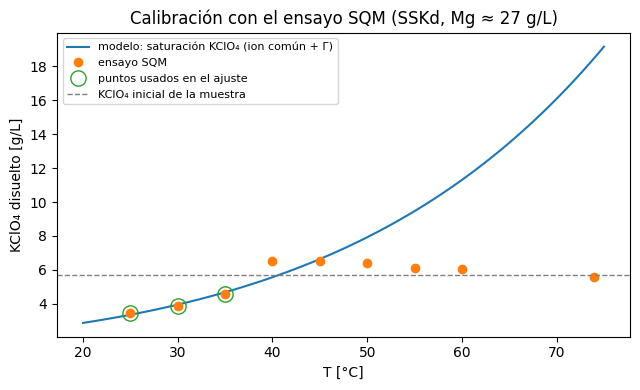

In [6]:
ENSAYO_SQM = pd.DataFrame({            # Informaciones Varias.docx, SQM
    "T_C":       [74,   60,   55,   50,   45,   40,   35,   30,   25],
    "KClO4_g_L": [5.57, 6.05, 6.12, 6.40, 6.54, 6.54, 4.59, 3.90, 3.48]})
saturado = ENSAYO_SQM["T_C"] <= 35

def predecir_ensayo(T_C, termo=TERMO, comp0=COMP["SSKd"], w_agua=W_AGUA_KG_L):
    """g/L de KClO4 disuelto predichos (licor saturado en KNO3 y KClO4)."""
    mK = m_K_eq_KNO3(T_C, comp0, termo)
    return m_ClO4_sat(T_C, mK, comp0["Mg"], termo) * M["KClO4"] * w_agua

def _res(p):
    t = copy.deepcopy(TERMO); t["lnGamma0"]["KClO4"] = p[0]
    d = ENSAYO_SQM[saturado]
    return np.log(predecir_ensayo(d["T_C"].values, t)) - np.log(d["KClO4_g_L"].values)

fit_G = least_squares(_res, x0=[1.0])
TERMO["lnGamma0"]["KClO4"] = float(fit_G.x[0])
TERMO["m_Mg_ref"] = COMP["SSKd"]["Mg"]
print(f"ln Γ_KClO4,0 = {fit_G.x[0]:.3f}  (Γ = {np.exp(fit_G.x[0]):.2f}); "
      f"error relativo máx. en 25–35 °C = {100*np.max(np.abs(np.expm1(fit_G.fun))):.1f} %")

Tp = np.linspace(20, 75, 111)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(Tp, predecir_ensayo(Tp), label="modelo: saturación KClO₄ (ion común + Γ)")
ax.plot(ENSAYO_SQM["T_C"], ENSAYO_SQM["KClO4_g_L"], "o", label="ensayo SQM")
ax.plot(ENSAYO_SQM["T_C"][saturado], ENSAYO_SQM["KClO4_g_L"][saturado], "o", mfc="none", ms=11, label="puntos usados en el ajuste")
ax.axhline(5.7, ls="--", c="0.5", lw=1, label="KClO₄ inicial de la muestra")
ax.set(xlabel="T [°C]", ylabel="KClO₄ disuelto [g/L]", title="Calibración con el ensayo SQM (SSKd, Mg ≈ 27 g/L)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 2.6 Holgura térmica y efectos del NaNO₃ y del Mg

La **holgura térmica** es la diferencia entre la temperatura de operación y la temperatura a la que el KClO₄ empezaría a precipitar ($\sigma_{KClO_4} = 0$). Es el indicador más útil para SQM: cuántos grados le quedan al cristalizador antes de contaminar el producto con KClO₄ sólido.

Abajo se calcula para el licor en equilibrio con KNO₃ y con el ClO₄ concentrado por la evaporación. Para el **Mg** se muestran **escenarios** de $k_{ClO_4,Mg}$, porque con un solo ensayo (un solo nivel de Mg) ese parámetro **no es identificable**. Las curvas con $k \neq 0$ son ilustrativas y no son datos.

T de saturación predicha para la muestra del ensayo: 40.7 °C (ensayo: inflexión cerca de 40 °C; modelo SQM: 42,5 °C)


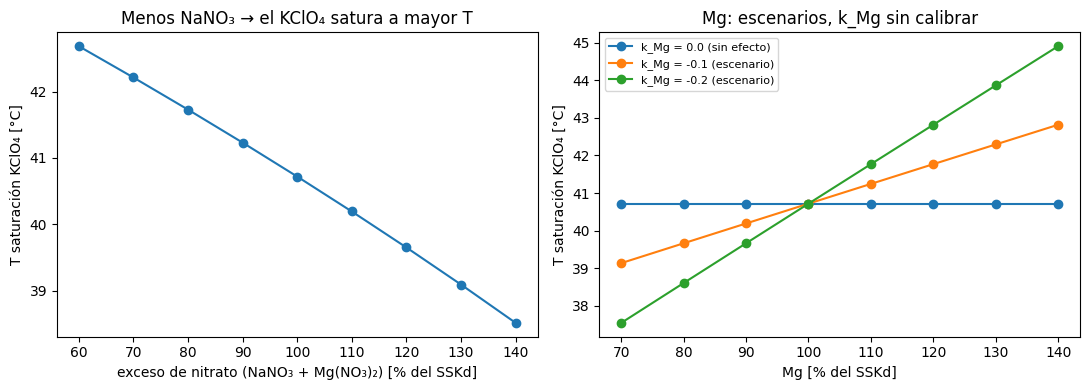

In [7]:
def T_saturacion_KClO4(comp, termo=TERMO, T_lo=5.0, T_hi=95.0):
    """T [°C] a la que sigma_KClO4 = 0 para un licor en equilibrio con KNO3 (comp: molalidades de entrada)."""
    def f(T):
        c = dict(comp); c["K"] = min(comp["K"], m_K_eq_KNO3(T, comp, termo))   # si el KNO3 está subsaturado, no cristaliza
        c["NO3"] = comp["NO3"] - (comp["K"] - c["K"])
        return sobresaturacion("KClO4", T, c, termo)
    if f(T_lo) < 0:  return np.nan     # no satura en el rango
    if f(T_hi) > 0:  return np.inf
    return brentq(f, T_lo, T_hi)

def holgura_termica(T_op, comp, termo=TERMO):
    return T_op - T_saturacion_KClO4(comp, termo)

# (a) Verificación con el ensayo: T a la que satura la muestra de SSKd
print(f"T de saturación predicha para la muestra del ensayo: {T_saturacion_KClO4(COMP['SSKd']):.1f} °C "
      "(ensayo: inflexión cerca de 40 °C; modelo SQM: 42,5 °C)")

# (b) Efecto del NaNO3 (sale del ion común, sin parámetros extra)
factores = np.linspace(0.6, 1.4, 9)
T_na = []
for f in factores:
    c = dict(COMP["SSKd"]); c["NO3"] = c["K"] + f * (COMP["SSKd"]["NO3"] - COMP["SSKd"]["K"])
    T_na.append(T_saturacion_KClO4(c))

# (c) Escenarios de Mg
mg_rel = np.linspace(0.7, 1.4, 8)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(100 * factores, T_na, "o-")
ax[0].set(xlabel="exceso de nitrato (NaNO₃ + Mg(NO₃)₂) [% del SSKd]", ylabel="T saturación KClO₄ [°C]",
          title="Menos NaNO₃ → el KClO₄ satura a mayor T")
for k in (0.0, -0.1, -0.2):
    t = copy.deepcopy(TERMO); t["k_Mg"]["KClO4"] = k
    Ts = [T_saturacion_KClO4({**COMP["SSKd"], "Mg": r * COMP["SSKd"]["Mg"]}, t) for r in mg_rel]
    ax[1].plot(100 * mg_rel, Ts, "o-", label=f"k_Mg = {k}" + (" (sin efecto)" if k == 0 else " (escenario)"))
ax[1].set(xlabel="Mg [% del SSKd]", ylabel="T saturación KClO₄ [°C]", title="Mg: escenarios, k_Mg sin calibrar")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

### 2.7 Resumen de la sección y pendientes

| Elemento | Estado | Procedencia |
|---|---|---|
| Curva KNO₃–agua (Apelblat) | ✅ | chemister.ru; verificar contra Perry/CRC |
| Curva KClO₄–agua (Apelblat) | ⚠ | datos dispersos; reemplazar por una tabla única (Linke & Seidell o CRC) |
| Sobresaturación única `sobresaturacion()` | ✅ | definición termodinámica para sal 1:1 |
| Ion común K⁺ / NO₃⁻ / ClO₄⁻ | ✅ | sin parámetros extra |
| Efecto NaNO₃ | ✅ | sale del ion común; coincide en signo con SQM |
| $\Gamma_{KClO_4,0}$ | ✅ | calibrado con el ensayo SQM (25–35 °C) |
| $\Gamma_{KNO_3,0}$ | ❌ | requiere KNO₃ en el MLK a T conocida |
| $k_{Mg}$ (KNO₃ y KClO₄) | ❌ | requiere un ensayo a otro nivel de Mg |
| $w_{agua}$ del licor | ❌ | medir densidad y humedad del SSKd |
| Unidades de AQ SSKd y Cl⁻ no analizado | ❌ | confirmar con SQM |

**Datos para pedir a SQM (agregar a la solicitud de muestreo):** densidad y contenido de agua del SSKd y del MLK; análisis de K, NO₃, Mg, Na, Cl y ClO₄ en el **MLK** de A3110 y A3210 junto con la temperatura de cada equipo (sirve para calibrar $\Gamma_{KNO_3}$); y un segundo ensayo de enfriamiento con SSKd a otro nivel de Mg (para $k_{Mg}$).

## 3. Datos de planta y caso base de operación

Esta sección reúne los datos de SQM que el modelo usa como entrada (alimentación, temperaturas, tiempos de residencia) y como referencia para calibrar y validar (granulometría de los under de A3110 y A3210). Cada valor lleva su fuente. Los que son supuestos del equipo están marcados como tales.

| Variable | Valor | Fuente |
|---|---|---|
| Alimentación SSKd a A3110 | 405,3 t/h (378,18 t/h + 27,14 t/h de agua de dilución) | Balance de masa detallado v6 |
| Temperatura de alimentación | 70 °C | Informe de parámetros, corriente 334 SSK-d |
| T de A3110 / A3210 | 55 °C / 40 °C | SQM, «Sistema de cristalización al vacío — Área 3000» (jul-2026) |
| Tiempo de residencia A3110 / A3210 | 0,7 h / 1,4 h | Protocolo experimental, Entrega 2 (supuesto del equipo) |
| Fracción de agua del SSKd | 0,3994 kg/kg | Informe de parámetros, corriente 334 SSK-d |
| Densidad del SSKd | 1518 kg/m³ | Informe de parámetros, corriente 334 SSK-d |
| Cp del licor | 2248 J/(kg·K) | Informe de parámetros, corriente 334 SSK-d |
| Densidad del licor en el cristalizador | 1470 kg/m³ | PFD GEA (repositorio, `params.py`) |
| Densidad del cristal de KNO₃ | 2110 kg/m³ | Perry, Tabla 2-1 |
| Cp del KNO₃ sólido | ≈ 950 J/(kg·K) | NIST Chemistry WebBook (≈ 96 J/(mol·K) a 25 °C); verificar |
| ΔH de cristalización del KNO₃ | −7,73 kcal/mol | SQM (jul-2026) |
| Calor latente del agua | λ(T) ≈ 2501 − 2,361·T [kJ/kg] | Aproximación lineal; error < 0,1 % frente a IAPWS entre 40 y 55 °C |
| Presión de vacío A3110 / A3210 | 11,59 kPa / 5,43 kPa | DWSIM, Entrega 2 (BPE resultante ≈ 6,2 °C / 5,6 °C) |

In [8]:
# =========================================================
# 3.1 Caso base de operación y propiedades
# =========================================================
OPER = {
    "F_SSKd_kg_s": (378.18 + 27.14) * 1000 / 3600,   # alimentación a A3110
    "T_feed_C": 70.0,
    "T_C":   {1: 55.0, 2: 40.0},                       # A3110, A3210
    "tau_h": {1: 0.7,  2: 1.4},
    "P_kPa": {1: 11.59, 2: 5.43},                      # solo para informar el vacío
}
PROP = {
    "x_agua_SSKd": 0.3994, "rho_SSKd": 1518.0, "rho_liq": 1470.0, "rho_c": 2110.0,
    "cp_liq": 2248.0, "cp_c": 950.0,
    "dHc_J_kg": 7.73 * 4184.0 / (M["KNO3"] / 1000),     # calor liberado al cristalizar [J/kg KNO3]
}
def lambda_agua(T_C):
    """Calor latente de vaporización del agua [J/kg] (aprox. lineal, 0-100 °C)."""
    return (2501.0 - 2.361 * T_C) * 1e3

def tsat_agua(P_kPa):
    """T de saturación del agua pura [°C] (Antoine)."""
    return 1730.63 / (8.07131 - np.log10(P_kPa / 0.133322)) - 233.426

for k in (1, 2):
    print(f"Etapa {k}: T = {OPER['T_C'][k]} °C, P = {OPER['P_kPa'][k]} kPa, "
          f"BPE implícito = {OPER['T_C'][k] - tsat_agua(OPER['P_kPa'][k]):.2f} °C")

Etapa 1: T = 55.0 °C, P = 11.59 kPa, BPE implícito = 6.20 °C
Etapa 2: T = 40.0 °C, P = 5.43 kPa, BPE implícito = 5.59 °C


### 3.2 Composición de la alimentación en base de agua

La composición iónica del SSKd viene de la sección 2 (molalidades). Lo que falta para cerrar la masa del licor (Na⁺, Cl⁻, SO₄²⁻, H₃BO₃ y otros no analizados en el SSKd) se agrupa como **«inertes»**: sales que no cristalizan en el rango de operación y que solo se concentran con la evaporación. Su masa se fija para que la fracción de agua del SSKd sea la del informe de SQM (0,3994).

In [9]:
FEED = dict(COMP["SSKd"])                              # mol / kg agua: K, NO3, Mg, ClO4
masa_ionica = sum(FEED[s] * M[s] / 1000 for s in ("K", "NO3", "Mg", "ClO4"))   # kg / kg agua
FEED["inertes_kg"] = 1 / PROP["x_agua_SSKd"] - 1 - masa_ionica                  # kg / kg agua
print(f"Por kg de agua: iones analizados = {masa_ionica:.3f} kg, inertes = {FEED['inertes_kg']:.3f} kg")
print(f"Agua alimentada = {OPER['F_SSKd_kg_s']*PROP['x_agua_SSKd']*3.6:.1f} t/h")
# Sobresaturación de la alimentación a 70, 55 y 40 °C (sin evaporar ni cristalizar)
for T in (70, 55, 40):
    print(f"  sigma_KNO3 del SSKd a {T} °C = {sobresaturacion('KNO3', T, FEED):+.3f}")

Por kg de agua: iones analizados = 1.151 kg, inertes = 0.353 kg
Agua alimentada = 161.9 t/h
  sigma_KNO3 del SSKd a 70 °C = -0.232
  sigma_KNO3 del SSKd a 55 °C = +0.101
  sigma_KNO3 del SSKd a 40 °C = +0.684


### 3.3 Granulometría de planta (referencia de calibración)

Tamizajes de los under de A3110 y A3210 (`Compilado cristalizadores NPT3.xlsx`, hojas AG, 15 al 31 de agosto de 2026): **21 tamizajes por equipo**. Se usa el **promedio del pasante acumulado en masa** por malla, con su desviación estándar como incertidumbre. El D50 que resulta (≈ 560 µm en A3110 y ≈ 520 µm en A3210) es consistente con el informe de seguimiento (541 y 514 µm).

Un tamiz deja pasar un cristal según su **dimensión menor**. Para cristales equidimensionales (granulares), todas las dimensiones son parecidas, así que la abertura de malla es directamente la longitud característica $L$ del modelo (sección 4).

In [10]:
MALLAS_UM = np.array([38, 53, 75, 106, 250, 500, 850, 2000.])
AG_PLANTA = {   # pasante acumulado [% masa]: promedio y desviación estándar de 21 tamizajes por equipo
    1: {"media": np.array([0.13, 0.31, 0.79, 4.77, 14.21, 43.06, 84.36, 97.52]),
        "sd":    np.array([0.12, 0.29, 0.59, 3.24, 5.73, 8.22, 5.13, 3.94])},
    2: {"media": np.array([0.15, 0.34, 0.77, 4.71, 14.47, 48.02, 84.27, 98.30]),
        "sd":    np.array([0.14, 0.31, 0.58, 3.18, 6.49, 6.27, 5.05, 2.94])},
}
def d_pct(mallas, pasante, q):
    """Tamaño [µm] al q % pasante (interpolación en log del tamaño)."""
    return float(np.exp(np.interp(q, pasante, np.log(mallas))))

for k, nombre in ((1, "A3110"), (2, "A3210")):
    m = AG_PLANTA[k]["media"]
    print(f"{nombre}: D10 = {d_pct(MALLAS_UM, m, 10):.0f} µm, D50 = {d_pct(MALLAS_UM, m, 50):.0f} µm, "
          f"D80 = {d_pct(MALLAS_UM, m, 80):.0f} µm, finos < 106 µm = {m[3]:.1f} %")

A3110: D10 = 171 µm, D50 = 547 µm, D80 = 804 µm, finos < 106 µm = 4.8 %
A3210: D10 = 169 µm, D50 = 515 µm, D80 = 798 µm, finos < 106 µm = 4.7 %


## 4. Factor de forma

**Forma base: granular (equidimensional).** Las fotografías de los under de A3110 y A3210 (`Compilado cristalizadores NPT3.xlsx`, hoja Fotos) muestran, en la mayoría de las muestras, cristales **equidimensionales y granulares**: compactos, con aristas redondeadas e irregulares. Eso difiere de la bibliografía, que describe al KNO₃ como acicular. La longitud característica $L$ es el tamaño de tamiz.

Para una partícula granular se usan dos parámetros:

$$k_v = \frac{V}{L^3}, \qquad \frac{k_a}{k_v} = \frac{6}{\psi} \;\;\Rightarrow\;\; a_s = \frac{k_a}{\rho_c\,k_v\,L} = \frac{6}{\psi\,\rho_c\,L}$$

- **$k_v$** convierte número de cristales en masa. Caso base: $k_v = \pi/6$, el valor usual para partículas equidimensionales caracterizadas por tamaño de tamiz.
- **$\psi \le 1$** (esfericidad) mide cuánto más superficie tiene la partícula que una esfera del mismo tamaño. Con $\psi = 1$, $k_a/k_v = 6$, igual que una esfera o un cubo ideales; con $\psi < 1$, la superficie aumenta. Caso base: $\psi = 1$ hasta tener un dato medido, con sensibilidad para $\psi$ entre 0,7 y 1.

**Qué controla cada parámetro**

1. **$k_v$ casi no cambia los resultados calibrados.** En la curva de tamizado, $k_v$ se cancela, porque el pasante en masa es $\sum N L^3$ acumulado dividido por el total. Además, el balance de soluto fija la masa de cristales: si $k_v$ baja, el modelo forma más cristales, y eso lo absorbe la constante de nucleación al recalibrar (sección 6). Lo que sí cambia es el número de cristales.
2. **$\psi$ controla la superficie específica** y, con ella, el licor adherido a la torta y el perclorato que entra al producto sin lavar (sección 7).

Se conserva también la función del prisma de sección cuadrada ($L \times L \times rL$), solo para evaluar las muestras alargadas que aparecen en algunas fotos de fines de agosto.

In [11]:
def forma_granular(kv=np.pi / 6, psi=1.0):
    """Factores de forma de una partícula granular (equidimensional): ka/kv = 6/psi."""
    return {"tipo": "granular", "kv": kv, "psi": psi, "ka": 6.0 * kv / psi}

def forma(r=1.0):
    """Prisma de sección cuadrada L x L x rL (solo para sensibilidad a cristales alargados)."""
    return {"tipo": "prisma", "r": r, "kv": r, "ka": 2.0 + 4.0 * r}

FORMA = forma_granular()    # CASO BASE: granular, kv = pi/6, psi = 1 (fotografías de planta)
def sup_especifica(L_m, f=FORMA):
    return f["ka"] / (PROP["rho_c"] * f["kv"] * L_m)       # m2 / kg de cristal
print("Caso base:", {k: round(v, 3) if isinstance(v, float) else v for k, v in FORMA.items()},
      f"| a_s(550 µm) = {sup_especifica(550e-6):.2f} m²/kg")
for psi in (1.0, 0.85, 0.7):
    f = forma_granular(psi=psi); print(f"  granular psi = {psi}: ka/kv = {f['ka']/f['kv']:.2f}, a_s(550 µm) = {sup_especifica(550e-6, f):.2f} m²/kg")
for r in (2, 3):
    f = forma(r); print(f"  prisma r = {r}: ka/kv = {f['ka']/f['kv']:.2f}, a_s(550 µm) = {sup_especifica(550e-6, f):.2f} m²/kg")

Caso base: {'tipo': 'granular', 'kv': 0.524, 'psi': 1.0, 'ka': 3.142} | a_s(550 µm) = 5.17 m²/kg
  granular psi = 1.0: ka/kv = 6.00, a_s(550 µm) = 5.17 m²/kg
  granular psi = 0.85: ka/kv = 7.06, a_s(550 µm) = 6.08 m²/kg
  granular psi = 0.7: ka/kv = 8.57, a_s(550 µm) = 7.39 m²/kg
  prisma r = 2: ka/kv = 5.00, a_s(550 µm) = 4.31 m²/kg
  prisma r = 3: ka/kv = 4.67, a_s(550 µm) = 4.02 m²/kg


## 5. Modelo dinámico de las dos etapas en serie

### 5.1 Planteamiento

Cada cristalizador (A3110 y A3210) es un tanque agitado al vacío con **temperatura fija por el lazo de vacío** e **inventario constante por el lazo de nivel**. La pulpa de A3110 (licor + cristales) alimenta a A3210, de modo que la segunda etapa recibe **cristales sembrados**.

**Estados de cada etapa**

- $W$: kg de agua; $n_K, n_{NO_3}, n_{ClO_4}, n_{Mg}$: mol disueltos; $I$: kg de inertes.
- $N_i$: número de cristales de KNO₃ en la clase de tamaño $i$; $z_i$: kg de ClO₄ incorporado en esos cristales.
- $P$: kg de KClO₄ sólido coprecipitado.

**Balances de materia** (para cada especie disuelta $s$):

$$\frac{dn_s}{dt} = \dot n_{s,in} - r_{out}\, n_s - \nu_s\, \dot R_{KNO_3} - \nu'_s\, \dot R_{KClO_4} - \dot R_{inc}\,\delta_{s,ClO_4}, \qquad \frac{dW}{dt} = \dot W_{in} - r_{out}W - \dot m_{evap}$$

- $\dot R_{KNO_3}$ sale de la PBE (masa de cristal que aparece por crecimiento y nucleación).
- $\dot R_{KClO_4}$ es la coprecipitación de KClO₄ cuando $\sigma_{KClO_4} > 0$.
- $\dot R_{inc}$ es el perclorato que queda atrapado en el KNO₃ que crece.

**Balance de población** (volúmenes finitos, esquema upwind):

$$\frac{dN_i}{dt} = \dot N_{i,in} + \big(F_{i-1/2} - F_{i+1/2}\big) + B\,\delta_{i,0} - r_{out}\, h_i\, N_i, \qquad F = G(L)\,\frac{N}{\Delta L}$$

- $h_i$ es la función de clasificación de la descarga. Vale 1 en MSMPR; el DTB podría tener clasificación, pero no está confirmado.
- Si $\sigma < 0$, $G < 0$: los cristales se disuelven.

**Balance de energía** (T fija, la evaporación se despeja):

$$\dot m_{evap}\,\lambda(T) = \dot m_{liq,in}\, c_{p,l}(T_{in} - T) + \dot m_{c,in}\, c_{p,c}(T_{in} - T) + \Delta H_c\, \dot R_{KNO_3} M_{KNO_3}$$

**Arranque.** Cada etapa parte llena de licor de alimentación con una carga de siembra (10 % en masa, con la CSD de planta). Con nucleación secundaria ($B_s \propto M_T$), un tanque sin cristales podría quedarse sin cristales, así que la siembra solo sirve para elegir el estado estacionario con cristales, que es el de planta. El resultado estacionario no depende de esa carga.

**Nivel constante.** La masa total de cada etapa ($M_k = \tau_k \dot m_{in,k}$) no cambia, así que $r_{out}$ se despeja de $\dot m_{out} = \dot m_{in} - \dot m_{evap}$.

### 5.2 Cinética

- **Crecimiento** dependiente del tamaño (forma ASL simplificada) con Arrhenius:
  $G = k_g\, e^{-E_g/R\,(1/T - 1/T_{ref})}\, \sigma^{g}\, (1 + \gamma L)$.
- **Nucleación primaria** $B_p = k_{bp}\,\sigma^{b_p}$ y **secundaria** $B_s = k_{bs}\,\sigma^{b_s}\, M_T^{j}$ ($M_T$ en kg de cristal por m³ de pulpa). En cristalizadores industriales con mucha masa de sólidos domina la secundaria.
- **Disolución** ($\sigma < 0$): $G = k_{dis}\,\sigma$.

Los exponentes se fijan en valores típicos de bibliografía ($g = 1$, $b_s = 2$, $j = 1$, $b_p = 5$). En la sección 6 se calibran $k_g$, $k_{bs}$ y $\gamma$ con la granulometría de planta.

### 5.3 Perclorato en el cristal

Se separan tres mecanismos:

1. **Incorporación durante el crecimiento** (sustitución, adsorción e inclusiones líquidas). El coeficiente de reparto efectivo combina Burton–Prim–Slichter con un término empírico de inclusiones:
   $k_{eff} = \dfrac{k_0}{k_0 + (1-k_0)\,e^{-G\delta/D}} + k_{inc}\left(\dfrac{G}{G_{ref}}\right)^{n}$, con $\dot R_{inc} = k_{eff}\, x_{ClO_4}\, \dot m_{crec}$.
   Con $\delta/D \sim 10^4$ s/m y $G \sim 10^{-8}$ m/s, el término BPS casi no depende de $G$. La dependencia con la velocidad de crecimiento viene sobre todo de las **inclusiones líquidas**, que aparecen cuando el cristal crece rápido.
2. **Coprecipitación de KClO₄** como fase sólida aparte cuando $\sigma_{KClO_4} > 0$, con cinética rápida (casi equilibrio).
3. **Licor adherido** a la torta, proporcional a la superficie específica (forma y CSD). Se calcula al final, en el postproceso de la sección 7.

⚠ $k_0$, $k_{inc}$, $n$, la cinética de coprecipitación y el espesor de película son **placeholders**. Se calibran con mediciones de ClO₄ en cristal **sin lavar** por equipo, que están incluidas en la solicitud de muestreo.

In [12]:
# =========================================================
# 5.4 Parámetros cinéticos y de impureza
# =========================================================
KIN = {
    "kg": 3e-6, "g": 1.0, "Eg": 0.0, "Tref": 40.0, "gamma": 0.0,     # kg [m/s]; gamma [1/m]
    "kbp": 1e3, "bp": 5.0,                                             # [#/(m3 s)]
    "kbs": 2e10, "bs": 2.0, "j": 1.0,                                   # [#/(m3 s)/(kg/m3)^j]
    "kdis": 1e-6,                                                      # [m/s] disolución
}
IMP = {   # PLACEHOLDERS: calibrar con ClO4 en cristal sin lavar
    "k0": 2e-3, "delta_D": 2e4, "kinc": 1e-2, "Gref": 1e-8, "n": 1.0,
    "kp_KClO4": 1e-4,          # [mol/(kg agua·s)] coprecipitación (rápida)
    "pelicula_m": None,        # espesor de licor adherido; se ancla en la sección 7
    "eta_lavado": 0.75,        # eficiencia de lavado en centrífuga (placeholder del repositorio)
}
PROC_KIN = {"kg": "calibrado (sección 6)", "kbs": "calibrado (sección 6)", "gamma": "calibrado (sección 6)",
            "kbp": "placeholder", "exponentes": "bibliografía típica (fijos)", "kdis": "placeholder",
            "IMP": "placeholders: no hay ClO4 sin lavar medido por equipo"}

# Malla de tamaños (geométrica, 1 µm - 3 mm)
NCLASES = 90
EDGES = np.concatenate([[0.0], np.geomspace(5e-6, 3e-3, NCLASES)])
DL = np.diff(EDGES); LC = 0.5 * (EDGES[1:] + EDGES[:-1])
L3 = (EDGES[1:]**4 - EDGES[:-1]**4) / (4 * DL)          # promedio de L^3 en la celda
L2 = (EDGES[1:]**3 - EDGES[:-1]**3) / (3 * DL)          # promedio de L^2 en la celda
NESP = 7                                                 # W, K, NO3, ClO4, Mg, I, P
NEST = NESP + 2 * NCLASES                                # + N_i y z_i
H_CLAS = np.ones(NCLASES)                                # clasificación de descarga (1 = MSMPR)

In [13]:
# =========================================================
# 5.5 Ecuaciones de una etapa y del tren de dos etapas
# =========================================================
def _desempacar(x):
    W, nK, nN, nP, nMg, I, P = x[:NESP]
    N = x[NESP:NESP + NCLASES]; z = x[NESP + NCLASES:]
    return W, nK, nN, nP, nMg, I, P, N, z

def tasas(x, T, kin=KIN, imp=IMP, f=None):
    """Variables algebraicas de una etapa: sobresaturaciones, G, B, masas, etc."""
    f = FORMA if f is None else f
    W, nK, nN, nP, nMg, I, P, N, z = _desempacar(x)
    W = max(W, 1e-9)
    comp = {"K": nK / W, "NO3": nN / W, "ClO4": nP / W, "Mg": nMg / W}
    sig = sobresaturacion("KNO3", T, comp)
    sigP = sobresaturacion("KClO4", T, comp)
    m_c = PROP["rho_c"] * f["kv"] * np.dot(N, L3)                       # kg KNO3 sólido
    m_liq = W + I + sum(comp[s] * W * M[s] / 1000 for s in ("K", "NO3", "ClO4", "Mg"))
    V = m_liq / PROP["rho_liq"] + (m_c + P) / PROP["rho_c"]             # m3 de pulpa
    MT = m_c / V
    arr = np.exp(-kin["Eg"] / R_GAS * (1 / (T + 273.15) - 1 / (kin["Tref"] + 273.15)))
    if sig >= 0:
        G = kin["kg"] * arr * sig ** kin["g"] * (1 + kin["gamma"] * EDGES[1:])   # en las caras superiores
        B = (kin["kbp"] * sig ** kin["bp"] + kin["kbs"] * sig ** kin["bs"] * MT ** kin["j"]) * V
    else:
        G = kin["kdis"] * sig * np.ones(NCLASES); B = 0.0
    return dict(comp=comp, sigma=sig, sigma_KClO4=sigP, G=G, B=B, m_c=m_c, m_liq=m_liq, V=V, MT=MT,
                x_ClO4=comp["ClO4"] * W * M["ClO4"] / 1000 / m_liq)

def rhs_etapa(x, T, entrada, M_tot, kin=KIN, imp=IMP, f=None):
    """Derivadas de una etapa. entrada: dict de flujos [unidades/s] y T_in.
    Devuelve (dx, salida) donde salida son los flujos que deja la etapa."""
    f = FORMA if f is None else f
    W, nK, nN, nP, nMg, I, P, N, z = _desempacar(x)
    a = tasas(x, T, kin, imp, f)
    G = a["G"]
    # --- PBE: flujos en las caras (upwind)
    dens = N / DL
    Fc = np.zeros(NCLASES + 1)                       # Fc[i+1] = flujo de la clase i a la i+1
    if a["sigma"] >= 0:
        Fc[1:-1] = G[:-1] * dens[:-1]
        Fc[-1] = 0.0                                 # sin salida por el borde superior
    else:
        Fc[1:] = G * np.append(dens[1:], 0.0)        # G<0: de i+1 hacia i
        Fc[0] = G[0] * dens[0]                       # disolución completa de la clase 0
    dN_crec = Fc[:-1] - Fc[1:]
    dN_crec[0] += a["B"]
    # razón ClO4/cristal transportada con el flujo
    ratio = np.divide(z, N, out=np.zeros_like(z), where=N > 1e-30)
    if a["sigma"] >= 0:
        Fz = np.concatenate([[0.0], Fc[1:-1] * ratio[:-1], [0.0]])
    else:
        Fz = np.concatenate([Fc[:1] * ratio[:1], Fc[1:-1] * ratio[1:], [0.0]])
    dz_crec = Fz[:-1] - Fz[1:]
    # masa formada por crecimiento + nucleación (consistente con m_c)
    mdot_crec = PROP["rho_c"] * f["kv"] * np.dot(dN_crec, L3)          # kg/s (negativo si disuelve)
    R_KNO3 = mdot_crec / (M["KNO3"] / 1000)                            # mol/s
    # --- Perclorato incorporado
    Gm = np.average(G, weights=np.maximum(N * L2, 1e-300)) if a["sigma"] > 0 else 0.0
    keff = imp["k0"] / (imp["k0"] + (1 - imp["k0"]) * np.exp(-Gm * imp["delta_D"])) \
           + imp["kinc"] * (Gm / imp["Gref"]) ** imp["n"]
    R_inc = keff * a["x_ClO4"] * max(mdot_crec, 0.0)                   # kg ClO4/s
    w_sup = np.maximum(N * L2 * np.maximum(G, 0), 0.0)
    dz_inc = R_inc * w_sup / w_sup.sum() if w_sup.sum() > 0 else np.zeros(NCLASES)
    ClO4_disuelto = -Fz[0] if a["sigma"] < 0 else 0.0                  # kg/s: ClO4 de cristales que se disuelven por completo
    # --- Coprecipitación KClO4 (cinética rápida)
    sP = a["sigma_KClO4"]
    Pp = max(P, 0.0)
    R_P = imp["kp_KClO4"] * W * (sP if sP > 0 else sP * Pp / (Pp + 1.0))  # mol/s; solo disuelve si hay sólido
    # --- Energía: evaporación
    T_in = entrada["T_in"]
    mliq_in = entrada["W"] + entrada["I"] + sum(entrada[s] * M[s] / 1000 for s in ("K", "NO3", "ClO4", "Mg"))
    mc_in = PROP["rho_c"] * f["kv"] * np.dot(entrada["N"], L3) + entrada["P"]
    m_evap = (mliq_in * PROP["cp_liq"] * (T_in - T) + mc_in * PROP["cp_c"] * (T_in - T)
              + PROP["dHc_J_kg"] * mdot_crec) / lambda_agua(T)
    # --- Nivel constante: r_out
    m_out = mliq_in + mc_in - m_evap
    m_c_clas = PROP["rho_c"] * f["kv"] * np.dot(H_CLAS * N, L3)
    r_out = m_out / (a["m_liq"] + m_c_clas + P)
    # --- Derivadas
    dW = entrada["W"] - r_out * W - m_evap
    dK = entrada["K"] - r_out * nK - R_KNO3 - R_P
    dN3 = entrada["NO3"] - r_out * nN - R_KNO3
    dCl = entrada["ClO4"] - r_out * nP - R_P + (ClO4_disuelto - R_inc) / (M["ClO4"] / 1000)
    dMg = entrada["Mg"] - r_out * nMg
    dI = entrada["I"] - r_out * I
    dPs = entrada["P"] - r_out * P + R_P * M["KClO4"] / 1000
    dNi = entrada["N"] + dN_crec - r_out * H_CLAS * N
    dzi = entrada["z"] + dz_crec + dz_inc - r_out * H_CLAS * z
    dx = np.concatenate([[dW, dK, dN3, dCl, dMg, dI, dPs], dNi, dzi])
    salida = {"W": r_out * W, "K": r_out * nK, "NO3": r_out * nN, "ClO4": r_out * nP, "Mg": r_out * nMg,
              "I": r_out * I, "P": r_out * P, "N": r_out * H_CLAS * N, "z": r_out * H_CLAS * z, "T_in": T}
    diag = dict(a, m_evap=m_evap, mdot_crec=mdot_crec, R_inc=R_inc, R_P=R_P, keff=keff, r_out=r_out, m_out=m_out)
    return dx, salida, diag

def entrada_SSKd(oper=OPER, feed=FEED):
    W = oper["F_SSKd_kg_s"] * PROP["x_agua_SSKd"]
    e = {s: feed[s] * W for s in ("K", "NO3", "ClO4", "Mg")}
    e.update(W=W, I=feed["inertes_kg"] * W, P=0.0, N=np.zeros(NCLASES), z=np.zeros(NCLASES), T_in=oper["T_feed_C"])
    return e

def inventarios(oper=OPER):
    """Masa total de cada etapa [kg] = tau * flujo másico de entrada (aprox. con la alimentación)."""
    F = oper["F_SSKd_kg_s"]
    return {1: oper["tau_h"][1] * 3600 * F, 2: oper["tau_h"][2] * 3600 * F}

def rhs_tren(t, y, oper=OPER, kin=KIN, imp=IMP, f=None):
    x1, x2 = y[:NEST], y[NEST:]
    Mt = inventarios(oper)
    dx1, sal1, _ = rhs_etapa(x1, oper["T_C"][1], entrada_SSKd(oper), Mt[1], kin, imp, f)
    dx2, _, _ = rhs_etapa(x2, oper["T_C"][2], sal1, Mt[2], kin, imp, f)
    return np.concatenate([dx1, dx2])

def estado_inicial(oper=OPER, siembra=0.10, f=None):
    """Arranque: cada etapa llena de licor de alimentación más una carga de siembra (fracción másica `siembra`)
    con la CSD promedio de planta. La siembra solo elige el estado estacionario con cristales: con nucleación
    secundaria (B ∝ M_T) un tanque sin cristales podría quedarse sin cristales."""
    f = FORMA if f is None else f
    e = entrada_SSKd(oper); Mt = inventarios(oper)
    masa_por_kg_agua = 1 / PROP["x_agua_SSKd"]
    pas = np.interp(np.log(EDGES[1:]), np.log(MALLAS_UM * 1e-6), AG_PLANTA[1]["media"], left=0, right=100)
    w_clase = np.diff(np.concatenate([[0.0], pas])) / 100
    y = []
    for k in (1, 2):
        m_siembra = siembra * Mt[k]
        N0 = m_siembra * w_clase / (PROP["rho_c"] * f["kv"] * L3)
        W = (Mt[k] - m_siembra) / masa_por_kg_agua; fac = W / e["W"]
        y.append(np.concatenate([[W, e["K"]*fac, e["NO3"]*fac, e["ClO4"]*fac, e["Mg"]*fac, e["I"]*fac, 0.0],
                                 N0, np.zeros(NCLASES)]))
    return np.concatenate(y)

In [14]:
# =========================================================
# 5.6 Integración hasta el estado estacionario
# =========================================================
from scipy.sparse import lil_matrix
def _patron_jacobiano():
    """Patrón de dispersión del jacobiano (acelera BDF): cada etapa depende de sí misma; la 2 también de la 1."""
    S = lil_matrix((2 * NEST, 2 * NEST))
    S[:NEST, :NEST] = 1; S[NEST:, :] = 1
    return S.tocsr()
JAC_SP = _patron_jacobiano()

def simular(t_h=25.0, oper=OPER, kin=KIN, imp=IMP, f=None, y0=None, n_out=200):
    y0 = estado_inicial(oper) if y0 is None else y0
    sol = solve_ivp(rhs_tren, (0, t_h * 3600), y0, method="BDF", args=(oper, kin, imp, f),
                    t_eval=np.linspace(0, t_h * 3600, n_out), rtol=1e-6, atol=1e-9 * np.maximum(np.abs(y0), 1.0),
                    jac_sparsity=JAC_SP)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol

def resultados_etapa(x, k, entrada, oper=OPER, kin=KIN, imp=IMP, f=None):
    f = FORMA if f is None else f
    Mt = inventarios(oper)
    dx, sal, d = rhs_etapa(x, oper["T_C"][k], entrada, Mt[k], kin, imp, f)
    W, nK, nN, nP, nMg, I, P, N, z = _desempacar(x)
    masa_i = PROP["rho_c"] * f["kv"] * N * L3
    pas = 100 * np.cumsum(masa_i) / masa_i.sum() if masa_i.sum() > 0 else np.zeros(NCLASES)
    pas_mallas = np.interp(MALLAS_UM * 1e-6, EDGES[1:], pas)
    sol_pct = 100 * (d["m_c"] + P) / (d["m_liq"] + d["m_c"] + P)
    ppm_inc = 1e6 * z.sum() / max(d["m_c"], 1e-12)
    return dict(diag=d, salida=sal, pasante_mallas=pas_mallas, pasante=pas,
                D50_um=d_pct(MALLAS_UM, pas_mallas, 50) if masa_i.sum() > 0 else np.nan,
                solidos_pct=sol_pct, prod_t_h=3.6 * sal["N"] @ L3 * PROP["rho_c"] * f["kv"],
                evap_t_h=3.6 * d["m_evap"], ppm_inc=ppm_inc,
                ppm_coprec=1e6 * max(P, 0.0) / max(d["m_c"], 1e-12), ppm_clase=1e6 * np.divide(z, masa_i, out=np.zeros_like(z), where=masa_i > 0))

def resultados_tren(y, oper=OPER, kin=KIN, imp=IMP, f=None):
    e1 = entrada_SSKd(oper)
    r1 = resultados_etapa(y[:NEST], 1, e1, oper, kin, imp, f)
    r2 = resultados_etapa(y[NEST:], 2, r1["salida"], oper, kin, imp, f)
    return r1, r2

### 5.7 Verificación de los balances

Antes de calibrar, se comprueba que el modelo **conserve la masa**. Se integra con los parámetros iniciales hasta el estado estacionario y se compara, para el tren completo, lo que entra con lo que sale:

- **K⁺ y NO₃⁻:** lo que entra = lo disuelto que sale + lo cristalizado (KNO₃ y KClO₄).
- **Agua:** lo que entra = lo que sale en la pulpa + lo evaporado.
- **ClO₄⁻:** lo que entra = lo disuelto + lo incorporado al cristal + lo coprecipitado.

In [ ]:
def cierre_balances(y, oper=OPER, kin=KIN, imp=IMP, f=None):
    f = FORMA if f is None else f
    e = entrada_SSKd(oper)
    r1, r2 = resultados_tren(y, oper, kin, imp, f)
    s = r2["salida"]
    m_c_out = PROP["rho_c"] * f["kv"] * s["N"] @ L3
    nKNO3 = m_c_out / (M["KNO3"] / 1000); nKClO4 = s["P"] / (M["KClO4"] / 1000)
    evap = r1["diag"]["m_evap"] + r2["diag"]["m_evap"]
    err = {
        "K":    (s["K"] + nKNO3 + nKClO4 - e["K"]) / e["K"],
        "NO3":  (s["NO3"] + nKNO3 - e["NO3"]) / e["NO3"],
        "H2O":  (s["W"] + evap - e["W"]) / e["W"],
        "ClO4": (s["ClO4"] + s["z"].sum() / (M["ClO4"] / 1000) + nKClO4 - e["ClO4"]) / e["ClO4"],
    }
    return {k: float(v) for k, v in err.items()}

import time
t0 = time.time()
sol0 = simular(t_h=25.0)
print(f"Integración: {time.time()-t0:.1f} s, {sol0.t.size} puntos")
y_ss0 = sol0.y[:, -1]
print("Error relativo de cierre (debe ser ~0 en estado estacionario):",
      {k: f"{v:.1e}" for k, v in cierre_balances(y_ss0).items()})
deriva = np.abs(rhs_tren(0, y_ss0)) / np.maximum(np.abs(y_ss0), 1e-12)
print(f"Máxima derivada relativa al final: {np.nanmax(deriva[np.abs(y_ss0) > 1e-6*np.abs(y_ss0).max()]):.1e} 1/s")

## 6. Calibración de la cinética con la granulometría de planta

**Qué se puede identificar con una granulometría.** En estado estacionario, la CSD depende de cuántos cristales nacen ($B$) y de cuánto crecen durante su residencia ($G\tau$). La sobresaturación $\sigma$ no se mide: se ajusta sola hasta que el consumo de soluto iguala lo que entra. Si se elimina $\sigma$ entre $G = k_g\sigma$ y $B_s = k_{bs}\sigma^2 M_T$, queda

$$B_s = \frac{k_{bs}}{k_g^{2}}\, G^{2}\, M_T$$

Es decir, **la CSD solo determina la combinación $\theta = \log_{10}(k_{bs}/k_g^2)$**, no $k_g$ y $k_{bs}$ por separado. Por eso se calibran $\theta$ y $\gamma$ (crecimiento dependiente del tamaño), y $k_g$ queda fijo en un valor de referencia. $k_g$ solo fija el **nivel** de $\sigma$; $G$, la CSD y la producción no dependen de él. Para separar $k_g$ de $k_{bs}$ hay que medir $\sigma$, es decir, el KNO₃ del licor madre a la T de cada equipo (pendiente de la solicitud de muestreo).

Se ajustan los dos parámetros contra el pasante acumulado de **ambos** equipos (16 puntos: 8 mallas × 2 equipos). Cada residuo se pondera por la desviación estándar entre los 21 tamizajes, con un piso de 1 punto porcentual. Es un **ajuste al promedio de agosto**, no una validación: para validar hay que usar tamizajes de otro período.

In [ ]:
_cache = {"y": None}
KG_REF = 1e-5          # [m/s] fijo: solo define el nivel de sigma (no identificable con la CSD)
def kin_desde(p, kin_base=KIN):
    return dict(kin_base, kg=KG_REF, kbs=10 ** p[0] * KG_REF ** 2, gamma=p[1])

def residuos_calib(p):
    kin = kin_desde(p)
    y0 = _cache["y"]
    try:
        sol = simular(t_h=12.0 if y0 is not None else 25.0, kin=kin, y0=y0, n_out=2)
    except RuntimeError:
        return 1e3 * np.ones(16)
    y = sol.y[:, -1]; _cache["y"] = y
    r1, r2 = resultados_tren(y, kin=kin)
    return np.concatenate([(r["pasante_mallas"] - AG_PLANTA[k]["media"]) / np.maximum(AG_PLANTA[k]["sd"], 1.0)
                           for k, r in ((1, r1), (2, r2))])

p0 = [np.log10(KIN["kbs"] / KIN["kg"] ** 2), 0.0]
t0 = time.time()
fit_kin = least_squares(residuos_calib, p0, bounds=([10, 0], [30, 5e3]), x_scale=[1, 500], diff_step=1e-3, max_nfev=60)
KIN.update(kin_desde(fit_kin.x))
print(f"Calibración: {time.time()-t0:.0f} s, {fit_kin.nfev} evaluaciones; chi² = {2*fit_kin.cost:.2f} con 16 datos y 2 parámetros")
print(f"theta = log10(kbs/kg²) = {fit_kin.x[0]:.3f} | gamma = {fit_kin.x[1]:.1f} 1/m | (kg = {KG_REF:g} m/s fijo -> kbs = {KIN['kbs']:.3e})")

# Incertidumbre local (Gauss-Newton), solo para parámetros que no quedaron en un límite
libre = (fit_kin.x > np.array([10, 0]) + 1e-6) & (fit_kin.x < np.array([30, 5e3]) - 1e-6)
J = fit_kin.jac[:, libre]; dof = 16 - libre.sum(); s2 = 2 * fit_kin.cost / dof
sd = np.full(2, np.nan); sd[libre] = np.sqrt(np.diag(s2 * np.linalg.inv(J.T @ J)))
display(pd.DataFrame({"parámetro": ["theta = log10(kbs/kg²)", "gamma [1/m]"], "valor": fit_kin.x, "desv. est.": sd,
                      "estado": ["identificable" if l else "en el límite" for l in libre]}).round(3))
if not libre[1]:
    print("gamma quedó en 0: la granulometría promedio no pide crecimiento dependiente del tamaño (vale la ley de McCabe).")

Calibración: 20 s, 14 evaluaciones; chi² = 6.53 con 16 datos y 2 parámetros
theta = log10(kbs/kg²) = 19.148 | gamma = 0.0 1/m | (kg = 1e-05 m/s fijo -> kbs = 1.406e+09)


,parámetro,valor,desv. est.,estado
0,theta = log10(kbs/kg²),19.148,0.066,identificable
1,gamma [1/m],0.000,NaN,en el límite


gamma quedó en 0: la granulometría promedio no pide crecimiento dependiente del tamaño (vale la ley de McCabe).


## 7. Resultados del caso base

Con la cinética calibrada se integra el tren completo desde el arranque. Se revisan cuatro cosas:

1. La trayectoria hacia el estado estacionario.
2. La CSD frente a la de planta.
3. Los indicadores de operación: producción, evaporación, % de sólidos y sobresaturación.
4. El perclorato en el producto **sin lavar** y después del lavado, separado por mecanismo.

El licor adherido se calcula con un espesor de película anclado a una **humedad de torta del 3 %** para el D50 de planta. Esa humedad es un placeholder del repositorio y hay que medirla.

Cierre de balances: {'K': '1.8e-05', 'NO3': '1.8e-05', 'H2O': '1.6e-05', 'ClO4': '1.8e-05'}


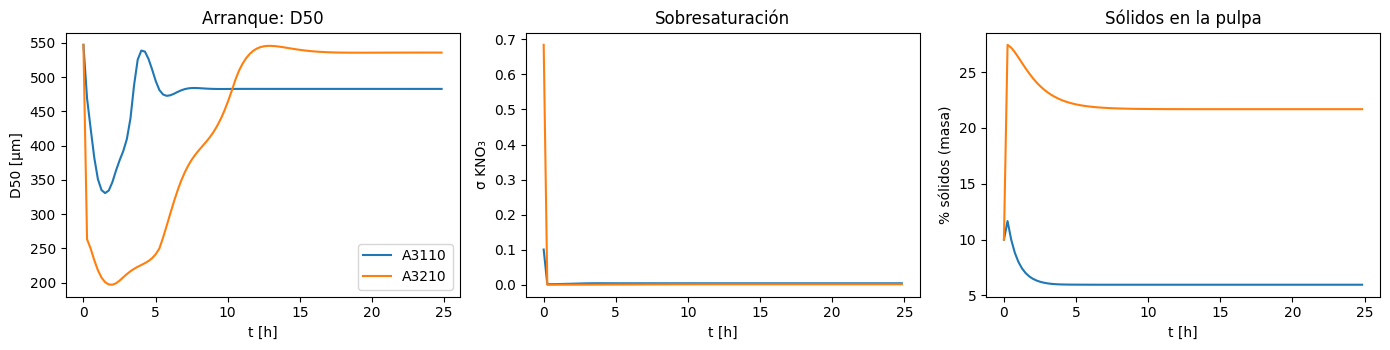

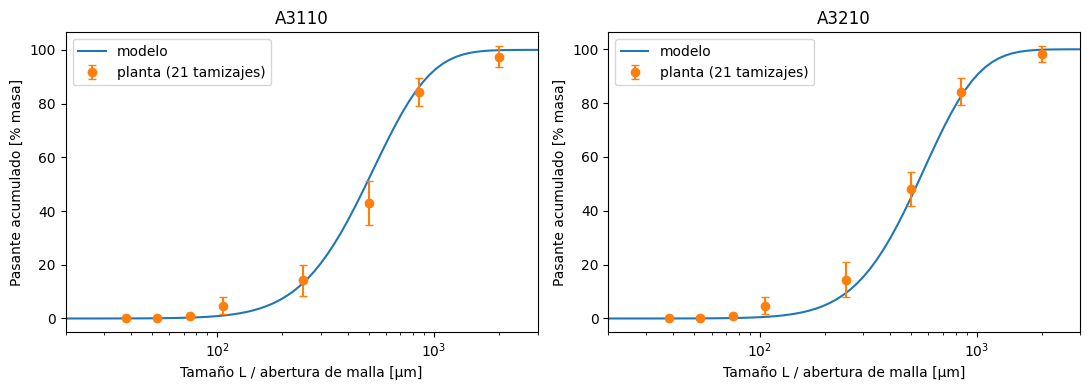

In [ ]:
_cache["y"] = None
sol = simular(t_h=25.0, n_out=300)
y_ss = sol.y[:, -1]
r1, r2 = resultados_tren(y_ss)
print("Cierre de balances:", {k: f"{v:.1e}" for k, v in cierre_balances(y_ss).items()})

# Trayectorias
th = sol.t / 3600
traj = {k: [] for k in ("D50_1", "D50_2", "sig1", "sig2", "sol1", "sol2")}
for i in range(0, sol.t.size, 3):
    a1, a2 = resultados_tren(sol.y[:, i])
    traj["D50_1"].append(a1["D50_um"]); traj["D50_2"].append(a2["D50_um"])
    traj["sig1"].append(a1["diag"]["sigma"]); traj["sig2"].append(a2["diag"]["sigma"])
    traj["sol1"].append(a1["solidos_pct"]); traj["sol2"].append(a2["solidos_pct"])
tt = th[::3]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(tt, traj["D50_1"], label="A3110"); ax[0].plot(tt, traj["D50_2"], label="A3210")
ax[0].set(xlabel="t [h]", ylabel="D50 [µm]", title="Arranque: D50"); ax[0].legend()
ax[1].plot(tt, traj["sig1"]); ax[1].plot(tt, traj["sig2"]); ax[1].set(xlabel="t [h]", ylabel="σ KNO₃", title="Sobresaturación")
ax[2].plot(tt, traj["sol1"]); ax[2].plot(tt, traj["sol2"]); ax[2].set(xlabel="t [h]", ylabel="% sólidos (masa)", title="Sólidos en la pulpa")
plt.tight_layout(); plt.show()

# CSD frente a planta
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, k, r, nombre in ((ax[0], 1, r1, "A3110"), (ax[1], 2, r2, "A3210")):
    a.plot(EDGES[1:] * 1e6, r["pasante"], label="modelo")
    a.errorbar(MALLAS_UM, AG_PLANTA[k]["media"], yerr=AG_PLANTA[k]["sd"], fmt="o", capsize=3, label="planta (21 tamizajes)")
    a.set(xscale="log", xlim=(20, 3000), xlabel="Tamaño L / abertura de malla [µm]", ylabel="Pasante acumulado [% masa]", title=nombre)
    a.legend()
plt.tight_layout(); plt.show()

In [ ]:
# Indicadores del caso base
def anclar_pelicula(r_ref, humedad=0.03, f=None):
    """Espesor de licor adherido [m] que da `humedad` (kg licor/kg torta) para la CSD de referencia."""
    f = FORMA if f is None else f
    a_s = sup_especifica(r_ref["D50_um"] * 1e-6, f)
    return humedad / (1 - humedad) / (PROP["rho_liq"] * a_s)
IMP["pelicula_m"] = anclar_pelicula(r2)

def ppm_producto(r, imp=IMP, f=None):
    f = FORMA if f is None else f
    a_s = sup_especifica(r["D50_um"] * 1e-6, f)
    w_adh = PROP["rho_liq"] * imp["pelicula_m"] * a_s                  # kg licor / kg cristal
    ppm_adh = 1e6 * w_adh * r["diag"]["x_ClO4"]
    return {"incorporado": r["ppm_inc"], "coprecipitado": r["ppm_coprec"], "adherido": ppm_adh,
            "total sin lavar": r["ppm_inc"] + r["ppm_coprec"] + ppm_adh,
            "total lavado": r["ppm_inc"] + r["ppm_coprec"] + ppm_adh * (1 - imp["eta_lavado"])}

tabla = {}
for nombre, k, r in (("A3110", 1, r1), ("A3210", 2, r2)):
    comp_out = r["diag"]["comp"]
    tabla[nombre] = {
        "T [°C]": OPER["T_C"][k], "σ KNO₃": r["diag"]["sigma"], "σ KClO₄": r["diag"]["sigma_KClO4"],
        "holgura térmica KClO₄ [°C]": holgura_termica(OPER["T_C"][k], comp_out),
        "G medio [m/s]": f'{np.average(r["diag"]["G"], weights=np.maximum(_desempacar(y_ss[(k-1)*NEST:k*NEST])[7]*L2, 1e-300)):.2e}',
        "D50 modelo / planta [µm]": f"{r['D50_um']:.0f} / {d_pct(MALLAS_UM, AG_PLANTA[k]['media'], 50):.0f}",
        "finos < 106 µm modelo / planta [%]": f"{r['pasante_mallas'][3]:.1f} / {AG_PLANTA[k]['media'][3]:.1f}",
        "% sólidos (masa)": r["solidos_pct"], "evaporación [t/h]": r["evap_t_h"],
        "KNO₃ sólido que sale [t/h]": r["prod_t_h"],
        **{f"ClO₄ {kk} [ppm]": v for kk, v in ppm_producto(r).items()},
    }
display(pd.DataFrame(tabla).map(lambda v: f"{v:.3g}" if isinstance(v, float) else v))
print("Referencia SQM/equipo: evaporación A3110 ≈ 10,03 t/h (balance v6); sólidos ≈ 13 % (A3110) y 20 % (A3210) (Entrega 2).")
print("Las ppm de ClO4 usan parámetros de incorporación PLACEHOLDER: muestran la estructura, no son predicción.")

,A3110,A3210
T [°C],55,40
σ KNO₃,0.00455,0.00176
σ KClO₄,-0.203,0.0151
holgura térmica KClO₄ [°C],13,-0.42
G medio [m/s],4.55e-08,1.76e-08
D50 modelo / planta [µm],483 / 547,536 / 515
finos < 106 µm modelo / planta [%],1.1 / 4.8,0.6 / 4.7
% sólidos (masa),5.96,21.7
evaporación [t/h],8.95,13.2
KNO₃ sólido que sale [t/h],23.6,82.9


Referencia SQM/equipo: evaporación A3110 ≈ 10,03 t/h (balance v6); sólidos ≈ 13 % (A3110) y 20 % (A3210) (Entrega 2).
Las ppm de ClO4 usan parámetros de incorporación PLACEHOLDER: muestran la estructura, no son predicción.


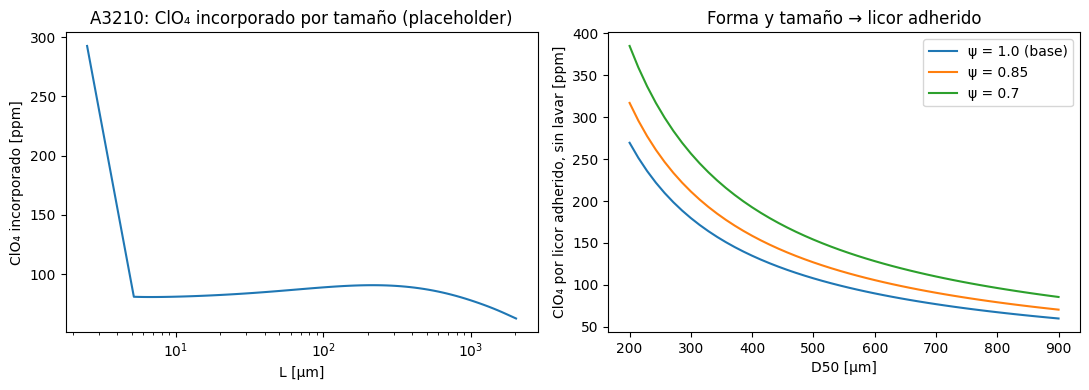

In [ ]:
# ClO4 por clase de tamaño en el producto de A3210 y efecto de la esfericidad (psi) sobre el licor adherido
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
msk = r2["pasante"] < 99.9
ax[0].plot(LC[msk] * 1e6, r2["ppm_clase"][msk])
ax[0].set(xscale="log", xlabel="L [µm]", ylabel="ClO₄ incorporado [ppm]", title="A3210: ClO₄ incorporado por tamaño (placeholder)")
for psi in (1.0, 0.85, 0.7):
    f = forma_granular(psi=psi); d = np.linspace(200, 900, 50)
    w = PROP["rho_liq"] * IMP["pelicula_m"] * sup_especifica(d * 1e-6, f)
    ax[1].plot(d, 1e6 * w * r2["diag"]["x_ClO4"], label=f"ψ = {psi}" + (" (base)" if psi == 1.0 else ""))
ax[1].set(xlabel="D50 [µm]", ylabel="ClO₄ por licor adherido, sin lavar [ppm]", title="Forma y tamaño → licor adherido")
ax[1].legend(); plt.tight_layout(); plt.show()

### 7.1 A3210 está en el borde de saturación del KClO₄

Con la termodinámica de la sección 2, el licor de A3210 a 40 °C queda **justo en la saturación del KClO₄** (σ ≈ +0,015, holgura ≈ −0,4 °C). Es coherente con el ensayo de SQM, cuya inflexión está cerca de 40 °C, y con que la evaporación concentre el perclorato entre las dos etapas.

Como la coprecipitación se modeló como **casi equilibrio**, todo el exceso precipita y el ClO₄ coprecipitado se dispara a miles de ppm. La planta no muestra eso, así que una de estas tres cosas es cierta:

1. el KClO₄ necesita superar una **zona metaestable** antes de nuclear (no hay dato de su ancho);
2. $\Gamma_{KClO_4}$ está algo subestimado (depende del supuesto de $w_{agua}$ y de un solo ensayo);
3. A3210 opera en promedio unas décimas de grado sobre 40 °C.

El resultado útil para SQM no es el número de ppm, sino **la forma de la curva**: en A3210, cada grado bajo el punto de saturación aumenta fuertemente el KClO₄ sólido. El barrido de abajo lo muestra y entrega la temperatura mínima segura de A3210 según el modelo.

,T A3210 [°C],σ KClO₄,holgura [°C],ClO₄ coprecipitado [ppm],ClO₄ lavado [ppm],KNO₃ producido [t/h],D50 [µm]
0,38.0,0.023,-0.628,2638.389,2745.857,88.951,540.351
1,39.0,0.019,-0.526,2276.519,2385.487,85.979,537.346
2,40.0,0.015,-0.420,1875.451,1985.889,82.912,535.743
3,41.0,0.011,-0.309,1429.144,1541.059,79.752,533.955
4,42.0,0.007,-0.194,930.097,1043.497,76.495,531.952
5,43.0,0.003,-0.074,369.029,483.928,73.140,529.695
6,44.0,-0.008,0.510,0.000,115.594,69.677,527.135
7,45.0,-0.027,1.637,0.000,115.182,66.099,524.215
8,46.0,-0.046,2.766,0.000,114.974,62.417,520.885


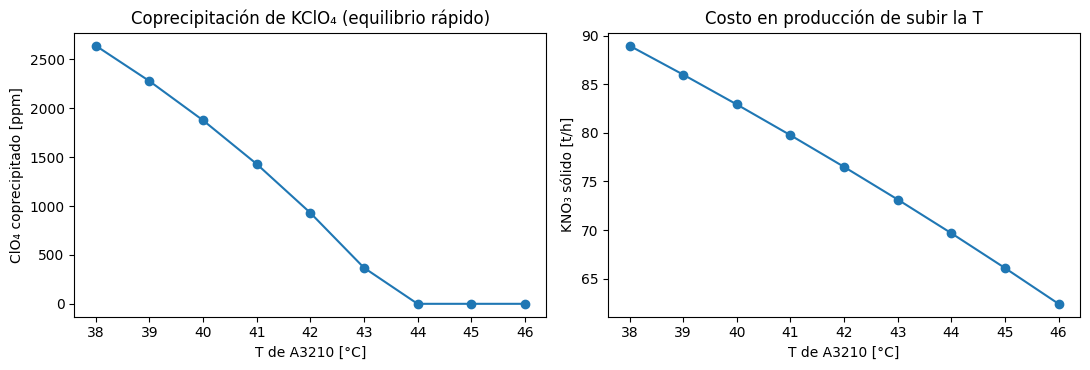

In [ ]:
T2_barrido = np.arange(38.0, 46.1, 1.0)
filas = []
y_prev = y_ss
for T2 in T2_barrido:
    op = copy.deepcopy(OPER); op["T_C"][2] = float(T2)
    s_ = simular(t_h=10.0, oper=op, y0=y_prev, n_out=2); y_prev = s_.y[:, -1]
    a1, a2 = resultados_tren(y_prev, oper=op)
    p = ppm_producto(a2)
    filas.append({"T A3210 [°C]": T2, "σ KClO₄": a2["diag"]["sigma_KClO4"],
                  "holgura [°C]": holgura_termica(T2, a2["diag"]["comp"]),
                  "ClO₄ coprecipitado [ppm]": p["coprecipitado"], "ClO₄ lavado [ppm]": p["total lavado"],
                  "KNO₃ producido [t/h]": a2["prod_t_h"], "D50 [µm]": a2["D50_um"]})
barrido = pd.DataFrame(filas)
display(barrido.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(barrido["T A3210 [°C]"], barrido["ClO₄ coprecipitado [ppm]"], "o-")
ax[0].set(xlabel="T de A3210 [°C]", ylabel="ClO₄ coprecipitado [ppm]", title="Coprecipitación de KClO₄ (equilibrio rápido)")
ax[1].plot(barrido["T A3210 [°C]"], barrido["KNO₃ producido [t/h]"], "o-")
ax[1].set(xlabel="T de A3210 [°C]", ylabel="KNO₃ sólido [t/h]", title="Costo en producción de subir la T")
plt.tight_layout(); plt.show()

### 7.2 Propuesta para SQM: incorporar la rugosidad del cristal

El modelo actual trata el licor adherido como una **película uniforme** sobre la superficie del cristal granular. Los cristales reales tienen rugosidad (cavidades, escalones, uniones entre cristales de un aglomerado) donde el licor madre queda retenido. Esta sección deja planteada la extensión del modelo. **No está implementada**: sus parámetros todavía no tienen datos.

**Por qué la rugosidad no se modela como más área.** Si las asperezas son más chicas que el espesor de la película (unos pocos µm), la película las cubre sin mojar más superficie. El efecto de la rugosidad es un **volumen adicional de licor retenido** que, además, se lava peor.

**Ecuaciones propuestas.** La superficie envolvente del cristal granular es

$$a_{env} = \frac{6}{\psi\,\rho_c\,L}$$

y el licor retenido por kg de cristal se reparte en dos compartimentos, película y cavidades:

$$w_{adh} = \rho_l\, a_{env}\,\big(\delta_f + \varepsilon_R\, h_R\big)$$

donde $\delta_f$ es el espesor de la película, $h_R$ la profundidad media de la rugosidad y $\varepsilon_R$ la fracción hueca de la capa rugosa. El perclorato que queda en el producto después del lavado es

$$\text{ppm}_{lav} = 10^6\, x_{ClO_4}\,\rho_l\, a_{env}\,\big[\delta_f\,(1-\eta_f) + \varepsilon_R h_R\,(1-\eta_R)\big]$$

- La película se desplaza con el agua de lavado, así que su eficiencia $\eta_f$ es alta.
- Las cavidades solo se vacían por **difusión**:
  $$\eta_R = 1 - \exp\!\left(-\frac{D(T)\, t_{lav}}{h_R^2}\right)$$
  El coeficiente de difusión $D$ aumenta con la temperatura porque baja la viscosidad del licor.

**Coherencia con los ensayos de lavado de SQM.** En el Compilado de pruebas, pasar de 75 a 100 L/min de agua de lavado no mejoró la remoción, y subir el agua a 40 °C sí la mejoró. Un modelo de una sola película no puede explicar las dos cosas a la vez. El de dos compartimentos sí: la meseta frente al caudal corresponde al licor de las cavidades, y la mejora con la temperatura es la firma de la difusión ($\eta_R$).

**Experimentos para obtener los parámetros** (planteados a nivel conceptual):

| Parámetro | Experimento | Qué se obtiene |
|---|---|---|
| $k_v$ | Pesar una fracción angosta de tamiz (por ejemplo 500–850 µm) y contar sus cristales | $k_v = m/(N\rho_c \bar L^3)$ |
| $\psi$ | Análisis de imágenes (área proyectada y perímetro) de unos 50 cristales por equipo | Esfericidad y superficie respecto de una esfera |
| $\delta_{eff} = \delta_f + \varepsilon_R h_R$ | Humedad de la torta centrifugada en dos o tres fracciones de tamiz | Pendiente de la humedad frente a $1/L$ |
| $\eta_f$, $\eta_R$ y la razón $\varepsilon_R h_R/\delta_f$ | Ensayos de lavado con distintos caudales de agua y dos temperaturas, midiendo ClO₄ en el cristal antes y después | Meseta (cavidades) y efecto de T (difusión) |
| $h_R$ | Imágenes de mayor aumento (lupa estereoscópica o SEM) | Verificación del orden de magnitud de la rugosidad |

Con estos parámetros, el modelo podría predecir cuánto perclorato se va con el lavado según la CSD, la forma y las condiciones de lavado. Eso conecta el cristalizador con el KPI del producto refinado (< 40 ppm).

## 8. Estado del modelo frente a la checklist y próximos pasos

| Requisito | Estado en este notebook |
|---|---|
| Solubilidad KNO₃ y KClO₄ en la salmuera (ion común + Γ) | ✅ sección 2 |
| Sobresaturación única | ✅ `sobresaturacion()` |
| Efecto NaNO₃ / Mg | ✅ / ⚠ $k_{Mg}$ sin calibrar |
| Evaporativo con balance de energía | ✅ sección 5 |
| Dos etapas en serie con siembra de la etapa 2 | ✅ |
| Balances por componente (K, NO₃, ClO₄, Mg, inertes, agua) con cierre | ✅ sección 5.7 |
| Nucleación primaria y secundaria, crecimiento dependiente del tamaño, disolución | ✅ |
| Factor de forma granular (fotos de planta), sensibilidad a ψ y a prismas | ✅ sección 4 |
| Rugosidad del cristal (licor en cavidades, lavado por difusión) | 📋 propuesta para SQM (sección 7.2) |
| Calibración con la granulometría de planta | ✅ sección 6: θ = log₁₀(k_bs/k_g²) identificable; k_g requiere medir σ (KNO₃ en el MLK); falta validar con otro período |
| Perclorato: incorporación (BPS + inclusiones), coprecipitación y licor adherido | ✅ estructura / ⚠ parámetros placeholder |
| Holgura térmica del KClO₄ por etapa | ✅ (A3210 queda en el borde: sección 7.1) |
| Aglomeración, atrición y clasificación del DTB | ❌ pendiente (las fotos muestran aglomerados) |
| Acople con condensadores y agua de enfriamiento | ❌ pendiente |

**Diferencias con planta a revisar:** el % de sólidos de A3110 (modelo ≈ 6 % frente a ≈ 13 % de la Entrega 2) depende de cuánto KNO₃ cristaliza a 55 °C, es decir, de $\Gamma_{KNO_3}$, que sigue sin calibrar. Los finos bajo 106 µm salen menores que en planta (≈ 1 % frente a ≈ 5 %), lo esperable sin atrición ni aglomeración.

**Datos que destraban lo pendiente:** ClO₄ en cristal **sin lavar** por equipo (para $k_0$, $k_{inc}$), $k_v$ y $\psi$ medidos, humedad de la torta, composición completa del MLK, un segundo ensayo de saturación a otro nivel de Mg y tamizajes de otro período para validar.